# TinyGeo playground

Edit the inputs below and run the cells to explore the first lookup milestone.

**The bundled database contains six invented reference points. This notebook tests
API behavior and spherical geometry, not real geographic coverage.** Country/region
fields belong to reference points and never establish where a query lies.

**Setup:** from the repository root, run `.venv/bin/python -m pip install -e '.[notebook]'`.
In VS Code select the project's `.venv/bin/python` kernel, then choose **Run All**.
Open this notebook from the repository root or its `notebooks/` directory.
The notebook runs offline once dependencies are installed. Track summaries and the
real GeoNames database are still pending.

In [ ]:
from pathlib import Path
from html import escape
from importlib.resources import files
from time import perf_counter
import json
import sys

# Prefer this checkout when running from the root or notebooks directory.
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/tinygeo/lookup.py").is_file()), None)
if root is not None:
    sys.path.insert(0, str(root / "src"))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, JSON, display
from tinygeo import Gazetteer, Reference, locate, locate_many


def table(rows):
    """Display small result tables without requiring pandas."""
    if not rows:
        print("No matching references.")
        return
    columns = list(rows[0])
    header = "".join(f"<th>{escape(str(c))}</th>" for c in columns)
    body = "".join("<tr>" + "".join(
        f"<td>{escape(str(row.get(c, '')))}</td>" for c in columns
    ) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"))


print("Ready — bundled lookups use synthetic-demo-v1.")

## 1. Try one coordinate

Change latitude, longitude, altitude, and `k`, then rerun this cell and the plot.
Try `(0, -179.9)` for the antimeridian, `(90, 0)` for the North Pole, or your own
coordinates. Large distances are expected with only six synthetic references.
Altitude is accepted and preserved but ignored for nearest-neighbor matching.

In [ ]:
lat = 0.0
lon = -179.9
altitude = 100.0
k = 3

result = locate(lat, lon, altitude=altitude, k=k)
print(result["description"])
print("Proximity:", result["confidence"], "| Altitude ignored:", result["altitude_ignored"])
table([{
    "reference": n["name"], "type": n["feature_type"],
    "distance km": round(n["distance_km"], 3),
    "bearing °": None if n["bearing_deg"] is None else round(n["bearing_deg"], 2),
} for n in result["neighbors"]])
display(JSON(result, expanded=False))

## 2. See the demo references

This is a longitude/latitude scatter plot, not a geographic projection or boundary
map. The left and right edges meet on the globe: points beside opposite edges can
be close together. Bearings are from the query toward the reference, clockwise
from north; undefined bearings are `None`.

In [ ]:
demo = json.loads(files("tinygeo").joinpath("resources/demo.json").read_text(encoding="utf-8"))
records = demo["records"]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.scatter([r["lon"] for r in records], [r["lat"] for r in records], label="Synthetic references")
for r in records:
    offset = (-8, 8) if r["lon"] > 150 else (8, 8)
    ax.annotate(r["name"], (r["lon"], r["lat"]), xytext=offset,
                textcoords="offset points", ha="right" if r["lon"] > 150 else "left")
ax.scatter([result["query"]["lon"]], [result["query"]["lat"]],
           marker="*", s=160, color="tab:red", label="Your query", zorder=3)
ax.set(xlim=(-185, 185), ylim=(-100, 105), xlabel="Longitude (degrees)",
       ylabel="Latitude (degrees)", title="Synthetic demo points — no real geographic coverage")
ax.grid(alpha=0.25)
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 3. Batch positions and feature filters

Rows are `(latitude, longitude, optional altitude)`. All rows in a batch must have
the same width. Output order matches input order. Any invalid row rejects the batch.

In [ ]:
positions = np.array([
    [0.0, 0.0, 0.0],
    [0.0, -179.9, 500.0],
    [89.95, 10.0, 1000.0],
    [-89.95, -20.0, 25.0],
])
results = locate_many(positions)
table([{
    "sample": i, "lat": r["query"]["lat"], "lon": r["query"]["lon"],
    "nearest": r["nearest"]["name"], "distance km": round(r["nearest"]["distance_km"], 2),
} for i, r in enumerate(results)])

In [ ]:
# Try "city", "landmark", {"city", "town", "remote_settlement"}, or [] for no matches.
feature_types = {"city", "town", "remote_settlement"}
filtered = locate(lat, lon, k=3, feature_types=feature_types)
print(filtered["description"])
table([{
    "field": field,
    "name": filtered[field]["name"] if filtered[field] else None,
    "distance km": round(filtered[field]["distance_km"], 2) if filtered[field] else None,
} for field in ("nearest", "nearest_any", "nearest_settlement", "nearest_landmark")])
# Only nearest/neighbors follow the filter; the class-specific results stay independent.

## 4. Supply your own references

Replace these invented points with locations you know to try a small personal
gazetteer. Give each reference a unique source ID. Set `synthetic=False` when using
real data, and record its provenance. Supported types are `city`, `town`,
`remote_settlement`, `landmark`, `mountain`, `lake`, `island`, and `other`.

In [ ]:
my_references = [
    Reference("example:harbor", "Example Harbor", 10.0, 20.0, "town"),
    Reference("example:peak", "Example Peak", 10.2, 20.3, "mountain"),
    Reference("example:monument", "Example Monument", 10.05, 20.05, "landmark"),
]
my_db = Gazetteer(my_references, dataset_id="my-synthetic-playground", synthetic=True)
my_result = my_db.locate(10.04, 20.06, k=3)
print(my_result["description"])
table([{"name": n["name"], "type": n["feature_type"],
        "distance km": round(n["distance_km"], 3)} for n in my_result["neighbors"]])

## 5. Run a few sanity checks

Distances use a spherical Earth with mean radius 6371.0088 km. These assertions
exercise the current API; they do not evaluate the usefulness of real-world data.

In [ ]:
earth_radius_km = 6371.0088
same = locate(0, 0)["nearest"]
assert np.isclose(same["distance_km"], 0, atol=1e-9)
assert same["bearing_deg"] is None

quarter = Gazetteer([Reference("test:east", "East", 0, 90, "city")]).locate(0, 0)["nearest"]
assert np.isclose(quarter["distance_km"], np.pi * earth_radius_km / 2)
assert np.isclose(quarter["bearing_deg"], 90)

seam = locate(0, -179.9)["nearest"]
assert seam["source_id"] == "demo:dateline"
assert np.isclose(seam["distance_km"], earth_radius_km * np.deg2rad(0.2))

pole = locate(90, 0)["nearest"]
assert pole["source_id"] == "demo:north"
assert pole["bearing_deg"] is None

assert locate(0, 0, altitude=12345)["nearest"] == locate(0, 0)["nearest"]
assert [r["query"]["lon"] for r in locate_many([[0, 90], [0, -90]])] == [90, -90]
print("Passed: identical point, quarter circle/bearing, antimeridian, pole, altitude, and batch order.")

for bad_position in [(91, 0), (0, 181), (np.nan, 0)]:
    try:
        locate(*bad_position)
    except ValueError as exc:
        print(f"Correctly rejected {bad_position}: {exc}")
    else:
        raise AssertionError(f"Accepted invalid position: {bad_position}")

## 6. Small timing experiment

Change `sample_count` to explore batch cost. This warms the default indexes first
and times the complete lookup including Python result dictionaries. It measures
**six synthetic references**, not performance of the planned 10,000-point database.

In [ ]:
sample_count = 1000
rng = np.random.default_rng(42)
# Uniform sampling over sphere area, rather than uniform latitude.
sample_positions = np.column_stack((
    np.rad2deg(np.arcsin(rng.uniform(-1, 1, sample_count))),
    rng.uniform(-180, 180, sample_count),
))
locate(0, 0)  # Warm the dataset and default indexes.
start = perf_counter()
sample_results = locate_many(sample_positions)
elapsed = perf_counter() - start
print(f"{len(sample_results):,} samples in {elapsed:.3f} s ({len(sample_results) / elapsed:,.0f} samples/s)")
print("Synthetic dataset only; timings vary with machine and sample count.")

## 7. Real database coverage — Robinson world map

Plot every reference in the current real `db`, colored by `feature_type`. If `db`
is not loaded, this cell opens the generated **10,000-point external dataset**.
The legend includes counts for the types actually present (the default city source
contains settlements). This cell can run independently of the earlier demo cells.

Cartopy is an optional **notebook-only** dependency: install with
`.venv/bin/python -m pip install -e '.[notebook]'` if needed. The first render fetches
Natural Earth's small 110m land/coastline layers into ignored
`data_sources/cartopy/`; later renders use that cache.

Projection: [Cartopy Robinson](https://cartopy.readthedocs.io/stable/reference/projections.html#cartopy.crs.Robinson).
Basemap: [Natural Earth, public domain](https://www.naturalearthdata.com/about/terms-of-use/).

Matplotlib is building the font cache; this may take a moment.


/Users/leif/Documents/sinkt/SourceCode/Python/052_EarthScience/001_fast_reverse_geocoder/.venv/lib/python3.13/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


/Users/leif/Documents/sinkt/SourceCode/Python/052_EarthScience/001_fast_reverse_geocoder/.venv/lib/python3.13/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


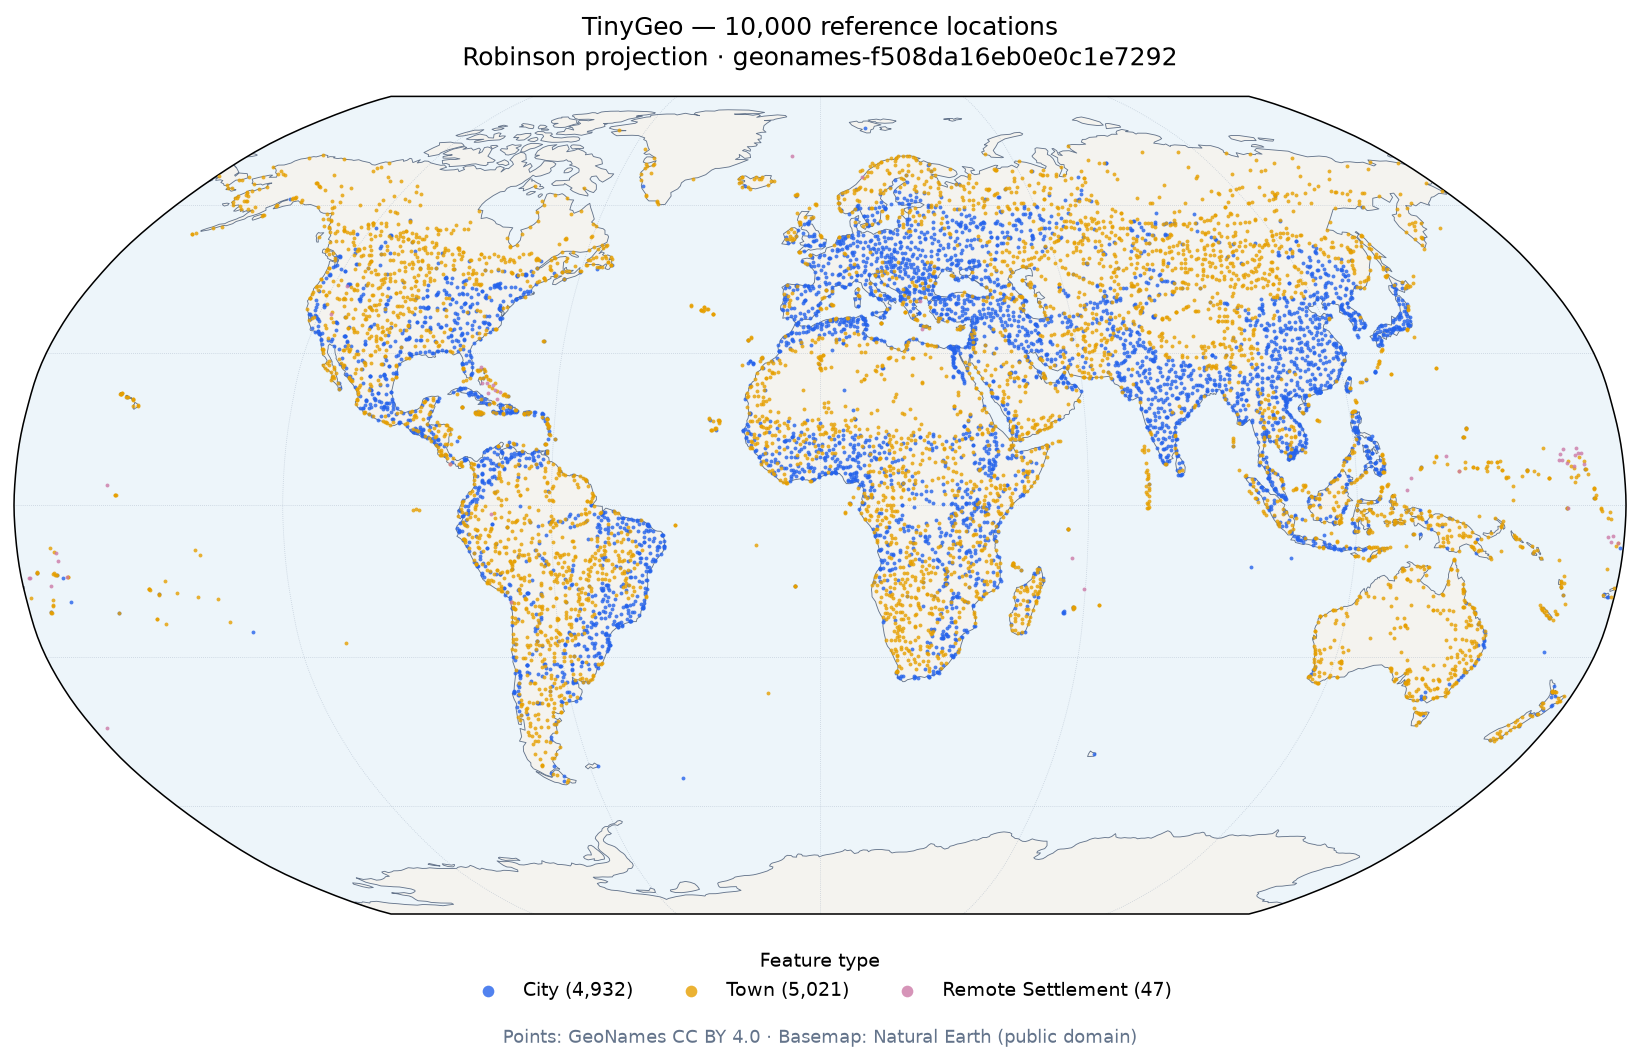

In [1]:
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from tinygeo import Gazetteer

plot_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "src/tinygeo/lookup.py").is_file()), None)
if plot_root is None:
    raise RuntimeError("Run this notebook from the project root or its notebooks/ directory.")

# Use the active real gazetteer, without changing the notebook's db variable.
map_db = globals().get("db")
if map_db is None or map_db.synthetic:
    map_db = Gazetteer.from_file(
        plot_root / "dist/tinygeo-pythonista-external-10000/dataset.json.gz"
    )

# Keep first-use basemap downloads inside the project's ignored source cache.
cartopy.config["data_dir"] = plot_root / "data_sources/cartopy"
map_coordinates = np.array([(r.lon, r.lat) for r in map_db.records])
map_types = np.array([r.feature_type for r in map_db.records])
map_counts = Counter(map_types)
map_colors = {
    "city": "#2563eb", "town": "#e69f00", "remote_settlement": "#cc79a7",
    "landmark": "#d55e00", "mountain": "#8c564b", "lake": "#56b4e9",
    "island": "#009e73", "other": "#6b7280",
}

fig_robinson = plt.figure(figsize=(15, 8), dpi=140, facecolor="white")
ax_robinson = fig_robinson.add_subplot(1, 1, 1, projection=ccrs.Robinson())
ax_robinson.set_global()
ax_robinson.set_facecolor("#edf5fa")
ax_robinson.add_feature(cfeature.LAND.with_scale("110m"), facecolor="#f4f3ef", edgecolor="none")
ax_robinson.coastlines(resolution="110m", linewidth=0.45, color="#64748b")
ax_robinson.gridlines(xlocs=range(-180, 181, 60), ylocs=range(-60, 61, 30),
                     linewidth=0.4, color="#94a3b8", alpha=0.5, linestyle=":")

for feature_type, color in map_colors.items():
    mask = map_types == feature_type
    if mask.any():
        ax_robinson.scatter(
            map_coordinates[mask, 0], map_coordinates[mask, 1],
            s=4, color=color, alpha=0.8, linewidths=0,
            transform=ccrs.PlateCarree(), rasterized=True, zorder=3,
            label=f"{feature_type.replace('_', ' ').title()} ({map_counts[feature_type]:,})",
        )

ax_robinson.set_title(
    f"TinyGeo — {len(map_db.records):,} reference locations\n"
    f"Robinson projection · {map_db.dataset_id}", fontsize=13, pad=16,
)
ax_robinson.legend(title="Feature type", loc="upper center", bbox_to_anchor=(0.5, -0.025),
                   ncol=min(4, len(map_counts)), markerscale=3, frameon=False)
fig_robinson.subplots_adjust(left=0.025, right=0.975, top=0.88, bottom=0.15)
fig_robinson.text(0.5, 0.035, "Points: GeoNames CC BY 4.0 · Basemap: Natural Earth (public domain)",
                  ha="center", fontsize=9, color="#64748b")
plt.show()